In [1]:
# Initialize Otter
import otter
grader = otter.Notebook("lab1.ipynb")

# Lab 1: Evaluation metrics

This notebook is Question 1 of Lab 1 on PrairieLearn. It has four coding parts, Questions 1.1 to 1.4. The other questions are on PrairieLearn, and some of them ask about the plots and results in this notebook.

- Write your code where you see `...`. Don't rename the variables or the function a question asks for, and don't move cells around: the autograder looks for them by name.
- Run `grader.check("q1_1")` (and so on) after a question to run its tests. A failing test tells you what went wrong.
- Before you submit, restart the kernel and run all cells (**Kernel > Restart Kernel and Run All Cells**), then save the notebook.
- Go back to the PrairieLearn page and click **Save & Grade**. You can grade as often as you like.

## Classification: predicting customer churn

In general, when a **dataset is imbalanced, accuracy does not provide the whole story**. In class, we looked at credit card fraud dataset which is a classic example of an imbalanced dataset. 

Another example is customer churn datasets. [Customer churn](https://en.wikipedia.org/wiki/Customer_attrition) refers to the notion of customers leaving a subscription service like Netflix. In this exercise, we will try to predict customer churn in a dataset where most of the customers stay with the service and a small minority cancel their subscription. The [Kaggle telecom customer churn dataset](https://www.kaggle.com/becksddf/churn-in-telecoms-dataset) is already in the `data/` folder.

The starter code below reads the data CSV as a pandas dataframe and splits it into 70% train and 30% test. Note that `churn` column in the dataset is the target variable where "True" means that the customer left the subscription (churned) and "False" means that they stayed. `True` is the positive class.

In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

warnings.filterwarnings(
    "ignore",
    message="You passed a `<class 'narwhals.stable.v1.DataFrame'>` to `is_pandas_dataframe`.",
    category=UserWarning
)


df = pd.read_csv("data/bigml_59c28831336c6604c800002a.csv", encoding="utf-8")
df['area code'] = df['area code'].astype(object)
train_df, test_df = train_test_split(df, test_size=0.3, random_state=123)
train_df

,state,account length,area code,phone number,international plan,voice mail plan,number vmail messages,total day minutes,total day calls,total day charge,...,total eve calls,total eve charge,total night minutes,total night calls,total night charge,total intl minutes,total intl calls,total intl charge,customer service calls,churn
1402,NE,70,415,421-8535,no,no,0,213.4,86,36.28,...,77,17.40,256.6,101,11.55,5.7,4,1.54,1,False
1855,WI,67,510,417-2265,no,no,0,109.1,134,18.55,...,76,12.10,91.2,86,4.10,10.9,5,2.94,2,False
633,NJ,122,415,327-9341,no,yes,34,146.4,104,24.89,...,103,7.62,220.0,91,9.90,15.6,4,4.21,2,False
1483,NV,107,510,419-9688,yes,no,0,234.1,91,39.80,...,105,13.86,282.5,100,12.71,10.0,3,2.70,1,False
2638,HI,105,510,364-8128,no,no,0,125.4,116,21.32,...,95,22.23,241.6,104,10.87,11.4,9,3.08,2,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2154,WY,126,408,339-9798,yes,no,0,197.6,126,33.59,...,112,20.95,285.3,104,12.84,12.5,8,3.38,2,False
3089,WV,70,510,348-3777,no,yes,30,143.4,72,24.38,...,92,14.45,127.9,68,5.76,9.4,4,2.54,3,False
1766,NJ,125,415,406-6400,no,no,0,182.3,64,30.99,...,121,11.88,171.6,96,7.72,11.6,7,3.13,2,False
1122,NE,159,415,362-5111,no,no,0,189.1,105,32.15,...,147,20.92,242.0,106,10.89,10.4,5,2.81,1,True


In [3]:
train_df.info()

<class 'pandas.DataFrame'>
Index: 2333 entries, 1402 to 1346
Data columns (total 21 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   state                   2333 non-null   str    
 1   account length          2333 non-null   int64  
 2   area code               2333 non-null   object 
 3   phone number            2333 non-null   str    
 4   international plan      2333 non-null   str    
 5   voice mail plan         2333 non-null   str    
 6   number vmail messages   2333 non-null   int64  
 7   total day minutes       2333 non-null   float64
 8   total day calls         2333 non-null   int64  
 9   total day charge        2333 non-null   float64
 10  total eve minutes       2333 non-null   float64
 11  total eve calls         2333 non-null   int64  
 12  total eve charge        2333 non-null   float64
 13  total night minutes     2333 non-null   float64
 14  total night calls       2333 non-null   int64  
 15  

### Exploring the churn data

Before we build models, let's look at the training data. You don't need to change anything in these cells: run them and study the plots. Question 4 on PrairieLearn asks about them.

In [4]:
train_df["churn"].value_counts()

churn
False    1984
True      349
Name: count, dtype: int64

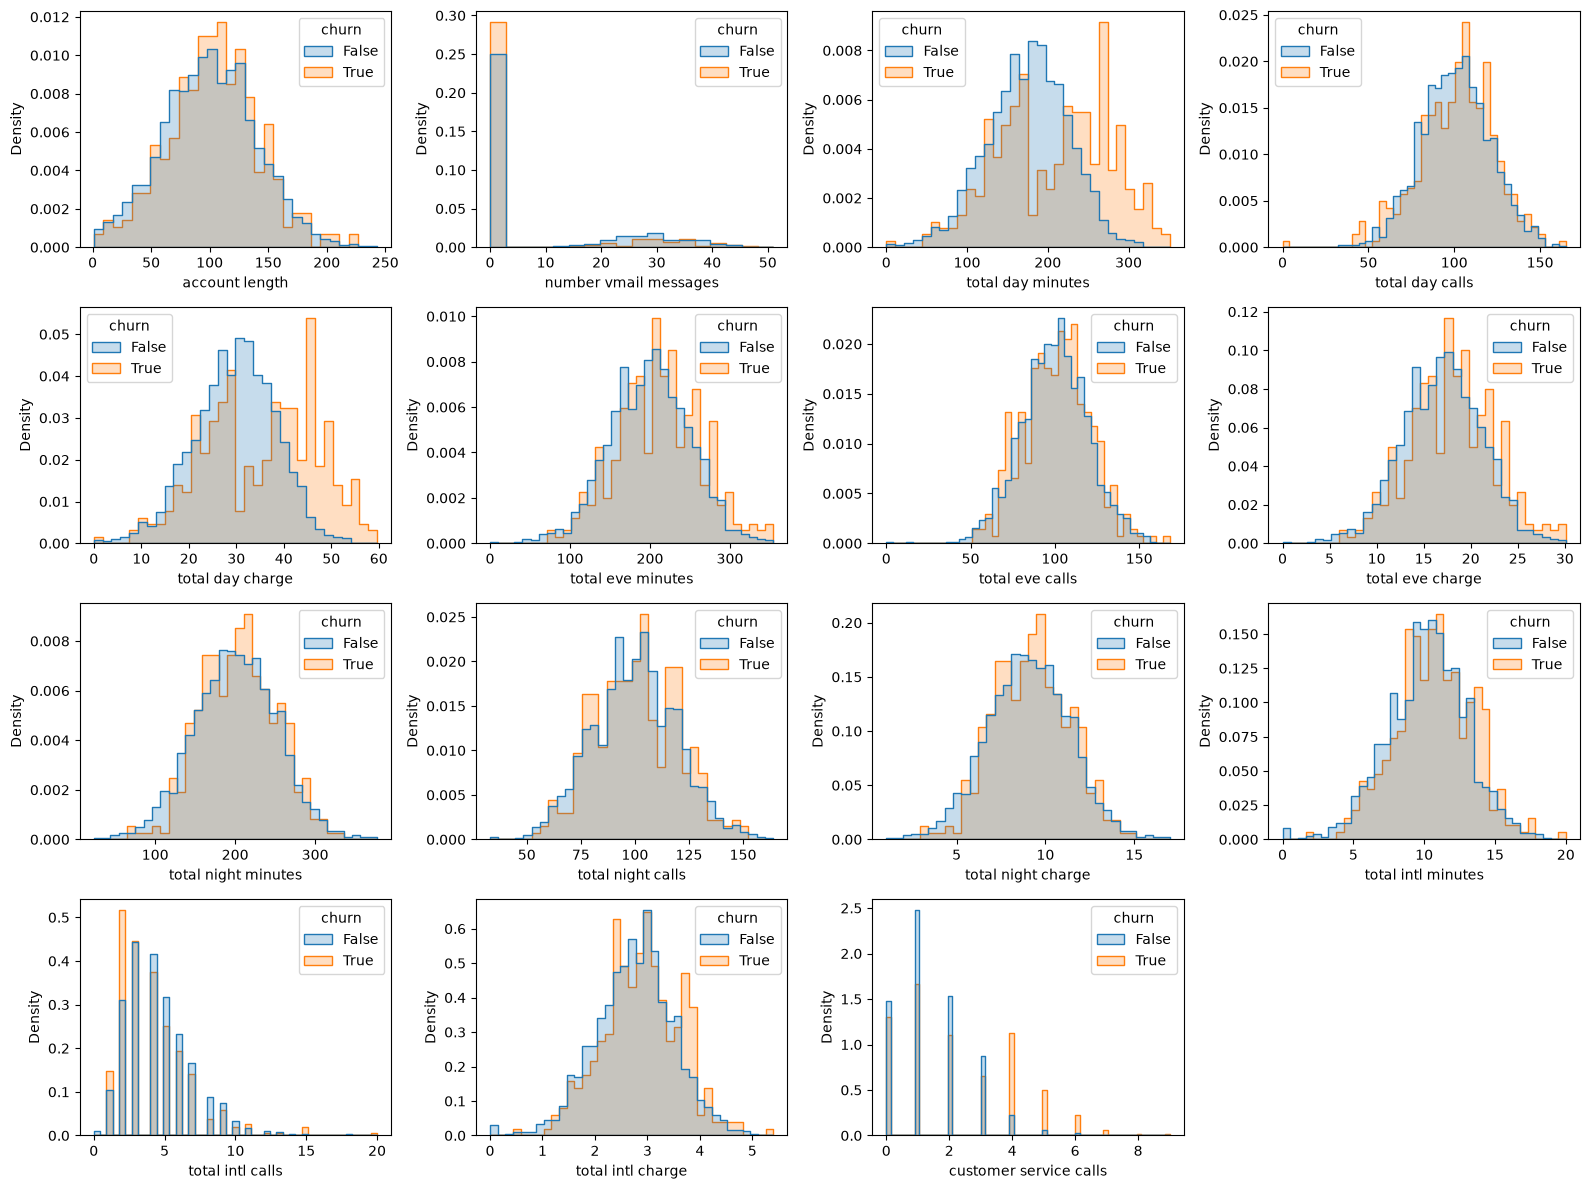

In [5]:
# Distribution of each numeric feature, for customers who stayed and customers who churned
import matplotlib.pyplot as plt
import seaborn as sns

numeric_columns = train_df.select_dtypes("number").columns
fig, axes = plt.subplots(4, 4, figsize=(16, 12))
for ax, column in zip(axes.flat, numeric_columns):
    # common_norm=False scales each group on its own, so the small churn group stays visible
    sns.histplot(data=train_df, x=column, hue="churn", stat="density", common_norm=False, element="step", ax=ax)
for ax in axes.flat[len(numeric_columns):]:
    ax.set_visible(False)
plt.tight_layout()

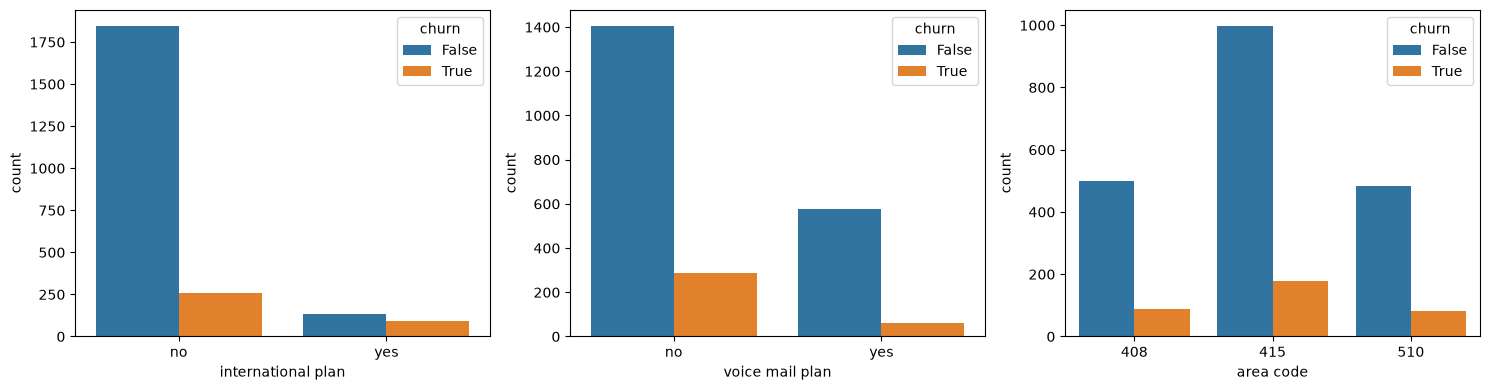

In [6]:
# Number of customers in each category, for customers who stayed and customers who churned
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, column in zip(axes, ["international plan", "voice mail plan", "area code"]):
    sns.countplot(data=train_df, x=column, hue="churn", ax=ax)
plt.tight_layout()

<Axes: >

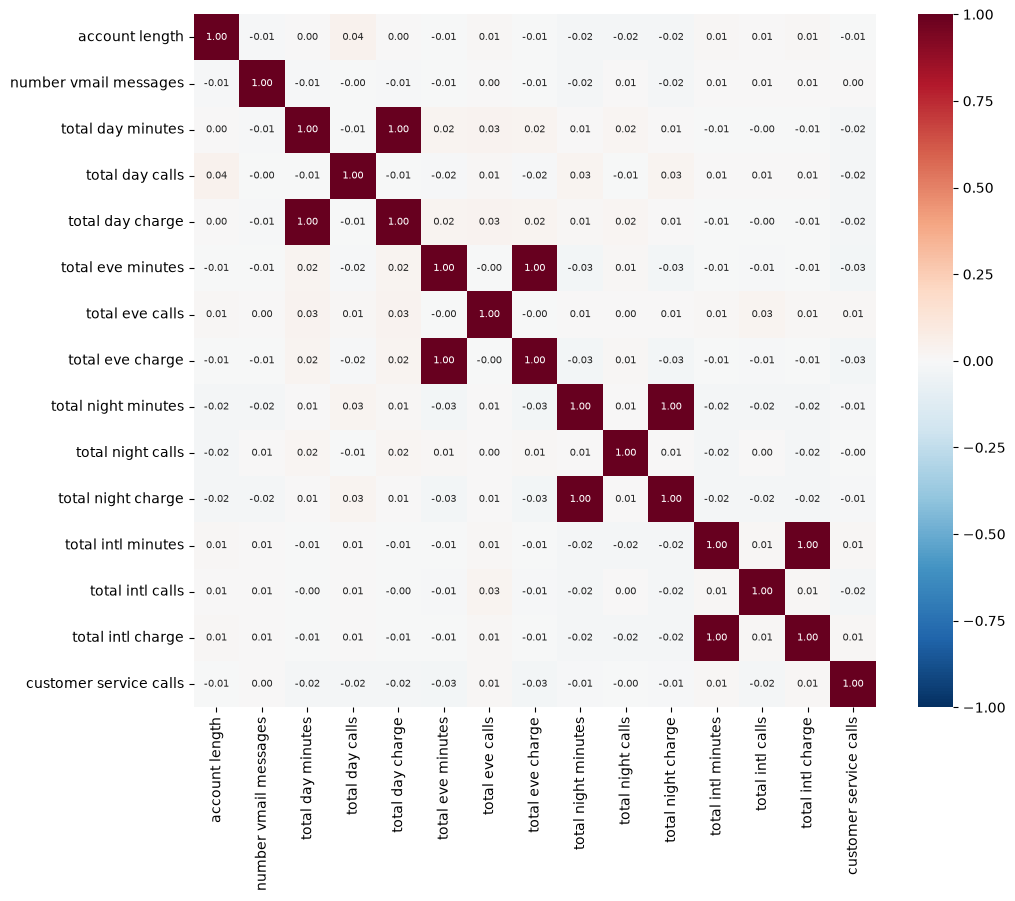

In [7]:
# Correlations between the numeric features
plt.figure(figsize=(11, 9))
sns.heatmap(
    train_df.select_dtypes("number").corr(),
    cmap="RdBu_r", vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 7},
)

### Optional: interactive Altair charts (local only)

The cells below make similar plots with `altair_ally`, which is not installed in the PrairieLearn workspace, so they give a `ModuleNotFoundError` there. Run them only on your own computer, in an environment made from the `pyproject.toml` in `lab1_local.zip` (for example with `uv sync`). You don't need them for any question.

In [8]:
# Look at the univariate distrbution for the quantitative variables
# `altair_ally` should be in your 573 environment already
import altair_ally as aly


aly.alt.data_transformers.enable('vegafusion')

aly.dist(train_df, color='churn')

alt.ConcatChart(...)

In [9]:
# Look at the univariate distrbutions (counts) for the categorical variables

# Changing churn to an object dtype just for the data passed to the chart
aly.dist(train_df.drop(columns='phone number').assign(churn=lambda df: df['churn'].astype(object)), dtype='object', color='churn')

alt.ConcatChart(...)

In [10]:
# Visualize pairwise correlations for the quantitative variables

aly.corr(train_df)

alt.ConcatChart(...)

In [11]:
# Visualize pairwise scatterplots for the quantitative variables with high correlations

columns_with_at_least_one_high_corr = [
    "customer service calls",
    "total day minutes",
    "total day charge",
    "total eve minutes",
    "total eve charge",
    "total night minutes",
    "total night charge",
    "total intl minutes",
    "total intl charge",
    "churn",  # Always interesting to include the target as well
]
# We are sampling the data frame to not saturate the charts, can be good to run this cell a few times
# (since we are coloring by the target, a 2D histogram wouldn't work well)
aly.pair(train_df[columns_with_at_least_one_high_corr].sample(300), color='churn')

alt.VConcatChart(...)

### Pre-processing

The code below creates a column transformer that:

- one-hot encodes `area code`, `international plan`, `voice mail plan`, and `state`, dropping the redundant column when a categorical feature is binary,
- drops the unique identifier `phone number`,
- standardizes the rest of the columns (mean 0 and standard deviation 1).

It then fits it on the training data so you can see the transformed columns. You don't need to change anything here.

In [12]:
# 1. Create the column transformer / preprocessor
# Imports
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler


# Lists of feature names
categorical_features = ["area code", "state", "international plan", "voice mail plan"]  
drop_features = ["phone number"]  
numeric_features = [x for x in train_df.columns if x not in ["churn"] + categorical_features + drop_features]  

# Create the column transformer
preprocessor = make_column_transformer(
    (StandardScaler(), numeric_features),
    (OneHotEncoder(drop='if_binary', handle_unknown="ignore", sparse_output=False), categorical_features),
    ("drop", drop_features),
)


# Show the preprocessor
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('standardscaler', ...), ('onehotencoder', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_n

In [13]:
# 2. Fit and transform on the training data
X_train = train_df.drop(columns=["churn"])
X_test = test_df.drop(columns=["churn"])
y_train = train_df["churn"]
y_test = test_df["churn"]

# This line nicely formats the feature names from `preprocessor.get_feature_names_out()` so that we can more easily use them below
preprocessor.verbose_feature_names_out = False
# Create a dataframe with the transformed features and column names
preprocessor.fit(X_train)
X_train_enc = pd.DataFrame(preprocessor.transform(X_train), index=X_train.index, columns=preprocessor.get_feature_names_out())  

# Show the transformed data
X_train_enc

,account length,number vmail messages,total day minutes,total day calls,total day charge,total eve minutes,total eve calls,total eve charge,total night minutes,total night calls,...,state_TX,state_UT,state_VA,state_VT,state_WA,state_WI,state_WV,state_WY,international plan_yes,voice mail plan_yes
1402,-0.767893,-0.587624,0.618769,-0.721211,0.618927,0.069871,-1.156734,0.069926,1.088667,0.052115,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1855,-0.843585,-0.587624,-1.293778,1.655252,-1.293517,-1.167277,-1.207278,-1.166291,-2.162302,-0.720990,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
633,0.544113,1.900976,-0.609809,0.169963,-0.609654,-2.210130,0.157417,-2.211244,0.369287,-0.463288,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1483,0.165650,-0.587624,0.998345,-0.473663,0.998611,-0.754894,0.258506,-0.755774,1.597736,0.000574,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2638,0.115188,-0.587624,-0.994886,0.764078,-0.994731,1.195994,-0.246937,1.196515,0.793839,0.206736,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2154,0.645037,-0.587624,0.329045,1.259175,0.328771,0.898602,0.612316,0.897957,1.652771,0.206736,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
3089,-0.767893,1.608200,-0.664820,-1.414346,-0.664665,-0.618094,-0.398570,-0.618157,-1.440956,-1.648715,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
1766,0.619806,-0.587624,0.048489,-1.810423,0.048322,-1.216842,1.067214,-1.217606,-0.582024,-0.205587,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1122,1.477656,-0.587624,0.173180,0.219472,0.173445,0.890672,2.381365,0.890960,0.801701,0.309816,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


<div class="alert alert-info">

### Question 1.1 (2 points)

1. Create a `DummyClassifier` and create a dataframe with the mean and std of the train and validation score from 5-fold cross-validation for the following metrics: accuracy, precision, recall, f1-score. Round the results to three decimal places.
2. The cross-validation gives a warning saying `UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples.` That is because the dummy classifier always predicts `False`, so it never predicts the positive class. Show that you understand how the dummy model works by using your cross-validation results to compute the proportion of customers churning in the training dataset.

</div>

_Points:_ 2

In [14]:
# 1. Dummy model
# Imports
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_validate

classification_metrics = ["accuracy", "precision", "recall", "f1"]
# The dummy model
dc = DummyClassifier(strategy="prior")
# The mean and std of the cross validated scores for all metrics as a dataframe
cross_val_results = {}
cross_val_results['dummy'] = pd.DataFrame(cross_validate(dc, X_train, y_train, scoring=classification_metrics, cv=5, return_train_score=True)).agg(['mean', 'std']).round(3).T

# Show the train and validation scores
cross_val_results['dummy']

/Users/itsluismario/Downloads/UBC/573/lab1_local/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/itsluismario/Downloads/UBC/573/lab1_local/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/itsluismario/Downloads/UBC/573/lab1_local/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _war

,mean,std
fit_time,0.001,0.000
score_time,0.006,0.001
test_accuracy,0.850,0.001
train_accuracy,0.850,0.000
test_precision,0.000,0.000
train_precision,0.000,0.000
test_recall,0.000,0.000
train_recall,0.000,0.000
test_f1,0.000,0.000
train_f1,0.000,0.000


In [15]:
# 2. Proportion of churning customers
proportion_churning = 1 - cross_val_results['dummy'].loc['train_accuracy', 'mean']

In [16]:
grader.check("q1_1")

q1_1 results: All test cases passed!
q1_1 - 1 message: ✅ Task q1_1.1: passed
q1_1 - 2 message: ✅ Task q1_1.2: passed

<div class="alert alert-info">

### Question 1.2 (6 points)

1. Create a `LogisticRegression` model and report the same metrics as for the `DummyClassifier` in Question 1.1. Use <code>max_iter=1000</code>.
2. Create an `SVC` model and report the same metrics as for the `DummyClassifier` in Question 1.1.
3. Examine the confusion matrix given by [`cross_val_predict`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_predict.html?highlight=cross_val_predict) for both classifiers. 

</div>

_Points:_ 6

In [17]:
# 1. Logistic regression
# Imports
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

# The logreg model pipeline
logreg = make_pipeline(preprocessor, LogisticRegression(max_iter=1000))

# The mean and std of the cross validated scores for all metrics as a dataframe
cross_val_results['logreg'] = pd.DataFrame(cross_validate(logreg, X_train, y_train, scoring=classification_metrics, cv=5, return_train_score=True)).agg(['mean', 'std']).round(3).T

# Show the train and validation scores
cross_val_results['logreg'] 

,mean,std
fit_time,0.017,0.003
score_time,0.009,0.001
test_accuracy,0.856,0.013
train_accuracy,0.867,0.002
test_precision,0.549,0.105
train_precision,0.642,0.013
test_recall,0.209,0.046
train_recall,0.249,0.015
test_f1,0.303,0.063
train_f1,0.358,0.017


In [18]:
# 2. Support vector classifier
# Imports
from sklearn.svm import SVC


# The svc model pipeline
svc = make_pipeline(preprocessor, SVC())

# The mean and std of the cross validated scores for all metrics as a dataframe
cross_val_results['svc'] = pd.DataFrame(cross_validate(svc, X_train, y_train, scoring=classification_metrics, cv=5, return_train_score=True)).agg(['mean', 'std']).round(3).T

# Show the train and validation scores
cross_val_results['svc'] 

,mean,std
fit_time,0.058,0.001
score_time,0.033,0.001
test_accuracy,0.904,0.010
train_accuracy,0.940,0.003
test_precision,0.928,0.035
train_precision,0.991,0.005
test_recall,0.390,0.071
train_recall,0.603,0.021
test_f1,0.545,0.071
train_f1,0.750,0.016


In [19]:
# 3. Confusion matrix for the logistic regression
# Imports
from sklearn.metrics import confusion_matrix 
from sklearn.model_selection import cross_val_predict

y_pred = cross_val_predict(logreg, X_train, y_train, cv=5)
confmat_logreg = confusion_matrix(y_train, y_pred)
# Show the matrix
confmat_logreg

array([[1924,   60],
       [ 276,   73]])

In [20]:
# 3. Confusion matrix for the SVC
y_pred = cross_val_predict(svc, X_train, y_train, cv=5)
confmat_svc = confusion_matrix(y_train, y_pred)

# Show the matrix
confmat_svc

array([[1973,   11],
       [ 213,  136]])

In [21]:
grader.check("q1_2")

q1_2 results: All test cases passed!
q1_2 - 1 message: ✅ Task q1_2.1: passed
q1_2 - 2 message: ✅ Task q1_2.2: passed
q1_2 - 3 message: ✅ Task q1_2.3: passed
q1_2 - 4 message: ✅ Task q1_2.4: passed
q1_2 - 5 message: ✅ Task q1_2.5: passed
q1_2 - 6 message: ✅ Task q1_2.6: passed

<div class="alert alert-info">

### Question 1.3 (4 points)

Perform the same tasks as in Question 1.2 but make sure that the class imbalance does not affect model performance as much for both the SVC and the logistic regression model, by setting the relevant parameter in the model initialization step. Use <code>max_iter=1000</code> for the logistic regression. 

</div>

_Points:_ 4

In [22]:
# 1. Balanced logistic regression
# The logreg model pipeline
logreg_bal = make_pipeline(preprocessor, LogisticRegression(max_iter=1000, class_weight="balanced"))

# The mean and std of the cross validated scores for all metrics as a dataframe
cross_val_results['logreg_bal'] = pd.DataFrame(cross_validate(logreg_bal, X_train, y_train, scoring=classification_metrics, cv=5, return_train_score=True)).agg(['mean', 'std']).round(3).T

# Show the train and validation scores
cross_val_results['logreg_bal'] 

,mean,std
fit_time,0.015,0.001
score_time,0.008,0.000
test_accuracy,0.761,0.019
train_accuracy,0.776,0.007
test_precision,0.351,0.021
train_precision,0.380,0.010
test_recall,0.699,0.029
train_recall,0.785,0.018
test_f1,0.467,0.019
train_f1,0.512,0.013


In [23]:
# 2. Balanced support vector classifier
# The svc model pipeline
svc_bal = make_pipeline(preprocessor, SVC(class_weight="balanced"))

# The mean and std of the cross validated scores for all metrics as a dataframe
cross_val_results['svc_bal'] = pd.DataFrame(cross_validate(svc_bal, X_train, y_train, scoring=classification_metrics, cv=5, return_train_score=True)).agg(['mean', 'std']).round(3).T

# Show the train and validation scores
cross_val_results['svc_bal'] 

,mean,std
fit_time,0.086,0.004
score_time,0.045,0.002
test_accuracy,0.883,0.010
train_accuracy,0.946,0.002
test_precision,0.593,0.030
train_precision,0.763,0.008
test_recall,0.711,0.046
train_recall,0.929,0.005
test_f1,0.646,0.029
train_f1,0.838,0.004


In [24]:
# 3. Confusion matrix for the logistic regression
# Imports
from sklearn.metrics import confusion_matrix 
from sklearn.model_selection import cross_val_predict

y_pred_logreg = cross_val_predict(logreg_bal, X_train, y_train, cv=5)

confmat_logreg_bal = confusion_matrix(y_train, y_pred_logreg)
# Show the matrix
confmat_logreg_bal

array([[1531,  453],
       [ 105,  244]])

In [25]:
# 3. Confusion matrix for the SVC
y_pred_svc = cross_val_predict(svc_bal, X_train, y_train, cv=5)

confmat_svc_bal = confusion_matrix(y_train, y_pred_svc)
# Show the matrix
confmat_svc_bal

array([[1813,  171],
       [ 101,  248]])

In [26]:
grader.check("q1_3")

q1_3 results: All test cases passed!
q1_3 - 1 message: ✅ Task q1_3.1: passed
q1_3 - 2 message: ✅ Task q1_3.2: passed
q1_3 - 3 message: ✅ Task q1_3.3: passed
q1_3 - 4 message: ✅ Task q1_3.4: passed
q1_3 - 5 message: ✅ Task q1_3.5: passed
q1_3 - 6 message: ✅ Task q1_3.6: passed

## Regression: California housing prices

For this exercise, we'll use the [California housing dataset](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.fetch_california_housing.html) from `sklearn datasets`. Each row is a district in California, and the target `MedHouseVal` is the median house value in units of $100,000. The code below loads the dataset from the `data/` folder.

In [27]:
housing_df = pd.read_csv("data/california_housing.csv")



### Pre-process dataset 

We are performing the following steps:

1. **Split the data** into train (80%) and test (20%) splits (using <code>random_state=123</code>).
2. **Feature transformation:** All our features are numeric. The only transformation which seems relevant here is scaling.
3. Separate `X` and `y` in train and test splits. 

</div>

In [28]:
# 1. Train/test split
train_df, test_df = train_test_split(housing_df, test_size=0.2, random_state=123)

In [29]:
# 2. Transformations if needed
# All our features are numeric. The only transformation which seems relevant here is scaling.
train_df.head()
train_df.describe()
preprocessor = StandardScaler()

In [30]:
# 3. X and y train/test
X_train, y_train = train_df.drop(columns=["MedHouseVal"]), train_df["MedHouseVal"]
X_test, y_test = test_df.drop(columns=["MedHouseVal"]), test_df["MedHouseVal"]

<div class="alert alert-info">

### Question 1.4 (4 points)

In this exercise, we are going to use a [`Ridge`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html) and a [`KNN`](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsRegressor.html) regression model (it is OK if you don't know exactly how these work in detail as we are mostly going to compare their scores on different metrics, but some basic knowledge about them is helpful). The code below creates a dictionary of different regressors (`models`) and different scoring metrics (`score_types_reg`).

`cross_validate` can score a model with several metrics at once. Pass a dict to `scoring`, where each key is the name you want in the results and each value is a scikit-learn scorer name. sklearn always treats a bigger score as better, so error metrics come with a minus sign, like `"neg_mean_squared_error"`. With `return_train_score=True`, the results get a `test_<key>` and a `train_<key>` entry for each metric.

Write a function `score_with_metrics(models, preprocessor, X, y, scoring)` that puts each model in a pipeline after `preprocessor`, runs 5-fold cross-validation with the given `scoring` and the training scores too, and returns a dataframe with one column per model holding the mean of each entry over the folds. The docstring shows the output for `scoring="r2"`. With `score_types_reg`, the rows are `fit_time`, `score_time`, then a `test_` and a `train_` row for each metric.

</div>

_Points:_ 4

In [31]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.neighbors import KNeighborsRegressor


dr = DummyRegressor()
models = {
    "Baseline": dr,
    "KNN_reg": KNeighborsRegressor(),
    "Ridge": Ridge(),
}

score_types_reg = {
    "neg_mean_squared_error": "neg_mean_squared_error",
    "neg_root_mean_squared_error": "neg_root_mean_squared_error",
    "neg_mape": "neg_mean_absolute_percentage_error",
    "r2": "r2",
}

In [34]:
import pandas as pd
from sklearn.model_selection import cross_validate
from sklearn.pipeline import make_pipeline


def score_with_metrics(models, preprocessor, X, y, scoring):
    """
    Return the mean cross-validation scores of each model as a dataframe.

    Each model is put in a pipeline after `preprocessor` and scored with
    5-fold cross-validation, on both the training and validation folds.

    Parameters
    ----------
    models : dict
        model names as keys and scikit-learn models as values
    preprocessor : scikit-learn transformer
        the transformer to apply before each model
    X : pandas.DataFrame
        the features
    y : pandas.Series
        the target
    scoring : str, list or dict
        the `scoring` argument to pass to `cross_validate`

    Returns
    -------
    pandas.DataFrame
        one column per model and one row per entry returned by
        `cross_validate` (such as `fit_time` and `test_r2`), holding the
        mean over the 5 folds

    Examples
    --------
    >>> score_with_metrics(models, preprocessor, X_train, y_train, "r2").round(3)
                 Baseline  KNN_reg  Ridge
    fit_time        0.002    0.005  0.003
    score_time      0.001    0.066  0.001
    test_score     -0.000    0.689  0.482
    train_score     0.000    0.795  0.606
    """
    cv_results = {}
    
    for name, model in models.items():
        pipe = make_pipeline(preprocessor, model)
        cv_results[name] = cross_validate(
            pipe, X, y, cv=5, scoring=scoring, return_train_score=True
        )

    return pd.DataFrame({
        name: pd.DataFrame(result).mean()
        for name, result in cv_results.items()
    })
    

In [35]:
# Check your function: the values we expect are in the comments
print(score_with_metrics(models, preprocessor, X_train, y_train, "r2").round(3).loc[["test_score", "train_score"]])
# expected
#              Baseline  KNN_reg  Ridge
# test_score       -0.0    0.689  0.482
# train_score       0.0    0.795  0.606
score_with_metrics(models, preprocessor, X_train, y_train, score_types_reg).round(3)
# expected test_neg_mape: Baseline -0.623, KNN_reg -0.240, Ridge -0.320

             Baseline  KNN_reg  Ridge
test_score       -0.0    0.689  0.482
train_score       0.0    0.795  0.606


,Baseline,KNN_reg,Ridge
fit_time,0.002,0.006,0.003
score_time,0.002,0.085,0.002
test_neg_mean_squared_error,-1.332,-0.414,-0.683
train_neg_mean_squared_error,-1.332,-0.273,-0.524
test_neg_root_mean_squared_error,-1.154,-0.643,-0.810
train_neg_root_mean_squared_error,-1.154,-0.522,-0.724
test_neg_mape,-0.623,-0.240,-0.320
train_neg_mape,-0.622,-0.193,-0.318
test_r2,-0.000,0.689,0.482
train_r2,0.000,0.795,0.606


In [36]:
grader.check("q1_4")

q1_4 results: All test cases passed!
q1_4 - 1 message: ✅ Task q1_4.1: passed
q1_4 - 2 message: ✅ Task q1_4.2: passed
q1_4 - 3 message: ✅ Task q1_4.3: passed

## Submission

Restart the kernel and run all cells, save the notebook, then go back to PrairieLearn and click **Save & Grade**.